# Feature extraction v2 — air phase first, then spin and fall signs

**Why v2?** The v1 features (whole-clip spin, grab) had near-zero correlations because:
- Spin was corrupted by camera-angle changes at cuts (np.unwrap treated them as body rotation)
- Grab detection conflates tuck with grab — can't disambiguate without ski detection
- Whole-clip approach/landing noise drowned out the actual trick

**This notebook's approach:**
1. **Detect the air phase** per camera shot using the centroid Y parabola — restrict all
   trick features to that window only
2. **Air-phase spin** — shoulder x-swap count restricted to the air window (ρ +0.43 vs
   manual total turns in the annotation study)
3. **Fall signs** — head-to-ankle proximity and sudden-stop ratio in the tail of the clip
4. **No grab** — wrist-ankle proximity cannot distinguish tuck from grab without ski keypoints

**Key design choices:**
- Air detection is per camera shot; the broadcast cuts to the wide shot at peak height so
  the apex is often at frame 0 of the jump shot — that is correct, not a bug
- Fall detection uses the last 20% of the clip (after landing), not the whole clip
- Shoulder x-swap uses 10% frame-width hysteresis to suppress keypoint jitter
- Never differentiate across a cut (`cut_frames` from `_pose_meta.json`)

In [1]:
import json
import numpy as np
import pandas as pd
from pathlib import Path

# ── paths ──────────────────────────────────────────────────────────────────
POSE_DIR   = Path("roi_pose_dataset")
SCORES_CSV = Path("scores/all_clips_scores.csv")
OUT_CSV    = Path("air_phase_features.csv")

CONF = 0.3   # keypoint confidence threshold

# ── COCO-17 indices ────────────────────────────────────────────────────────
NOSE             = 0
L_SH,  R_SH      = 5, 6
L_WR,  R_WR      = 9, 10
L_HIP, R_HIP     = 11, 12
L_KNE, R_KNE     = 13, 14
L_ANK, R_ANK     = 15, 16

# ── labels — single source ─────────────────────────────────────────────────
sc = pd.read_csv(SCORES_CSV, dtype={"clip_id": str})
sc = sc.rename(columns={"clip_id": "filename", "official_score_100": "target"})
# AQA pose files are named '001','002'… scores CSV uses 'aqa_001','aqa_002'
sc["filename"] = sc["filename"].str.replace("^aqa_", "", regex=True)
labels = sc.copy()

pose_files = sorted(POSE_DIR.glob("*_pose.npy"))
print(f"Labels  : {len(labels)} ({labels['target'].notna().sum()} scored)")
print(f"  AQA        : {(labels['dataset']=='aqa7').sum()}")
print(f"  competition: {(labels['dataset']=='competition').sum()}")
print(f"Pose    : {len(pose_files)} files in {POSE_DIR}")

Labels  : 392 (392 scored)
  AQA        : 175
  competition: 217
Pose    : 458 files in roi_pose_dataset


## Geometry helpers

In [2]:
def visible(frame, *indices):
    return all(frame[i, 2] >= CONF for i in indices)


def body_height_px(frame):
    """Shoulder-midpoint to ankle-midpoint Euclidean distance."""
    if not visible(frame, L_SH, R_SH, L_ANK, R_ANK):
        return np.nan
    sh  = (frame[L_SH,  :2] + frame[R_SH,  :2]) / 2.0
    ank = (frame[L_ANK, :2] + frame[R_ANK, :2]) / 2.0
    return float(np.linalg.norm(sh - ank))


def body_centroid(frame, min_kpts=4):
    """Confidence-weighted centroid of all visible keypoints."""
    mask = frame[:, 2] >= CONF
    if mask.sum() < min_kpts:
        return np.array([np.nan, np.nan])
    w = frame[mask, 2]
    return (frame[mask, :2] * w[:, None]).sum(0) / w.sum()


def gaussian_smooth(arr, sigma):
    """1-D Gaussian smooth, NaN-safe (fills NaN by linear interp first)."""
    n = len(arr)
    valid = ~np.isnan(arr)
    if valid.sum() < 2:
        return arr.copy()
    filled = np.interp(np.arange(n), np.where(valid)[0], arr[valid])
    half   = int(sigma * 3) | 1
    half  //= 2
    kernel = np.exp(-0.5 * (np.arange(-half, half + 1) / sigma) ** 2)
    kernel /= kernel.sum()
    return np.convolve(filled, kernel, mode="same")


print("Geometry helpers defined.")

Geometry helpers defined.


## Air phase detection

Looks at each camera shot independently and finds the one where the skier is highest.
Within that shot, the **air window** = frames where the centroid is at least
`AIR_LIFT_FRAC × body_height` above the shot's ground-level baseline.

**Why per-shot?** The camera angle (and hence centroid Y) changes at every cut.
Comparing centroid Y across shots gives meaningless numbers.

**Why apex-at-frame-0 is valid:** broadcast directors cut to the wide shot at peak height,
so the first frame of the jump shot often *is* the apex. The air window is then the whole
beginning of that shot until the skier descends past the threshold.

In [3]:
AIR_LIFT_FRAC  = 0.30   # skier must be this many body-heights above baseline to count as 'air'
AIR_MIN_S      = 0.40   # minimum credible air duration (seconds)
AIR_MIN_LIFT_PX = 20    # absolute minimum lift in pixels (guards tiny/far subjects)


def detect_air_phase(pose_seq, meta):
    """
    Detect the in-air window from the centroid Y trajectory, working per camera shot.

    Returns a dict with:
      air_detected    : 1 if a credible air window was found
      air_start       : first frame of air window
      air_end         : last frame of air window
      air_duration_s  : length of air window in seconds
      apex_frame      : frame with minimum centroid Y (highest point)
      apex_y_norm     : lift at apex in units of body height (bigger = higher jump)
      air_shot        : which camera shot the air window is in
    """
    fps     = float(meta.get("fps") or 59.94)
    n       = len(pose_seq)
    cuts    = sorted(int(c) for c in (meta.get("cut_frames") or []))
    # Shot boundaries: list of (start, end) frame index pairs
    bounds  = list(zip([0] + cuts, cuts + [n]))

    heights   = np.array([body_height_px(f) for f in pose_seq])
    median_h  = float(np.nanmedian(heights))
    centroids = np.array([body_centroid(f) for f in pose_seq])
    y_all     = centroids[:, 1]  # image Y: smaller = higher

    nan_result = dict(air_detected=0, air_start=np.nan, air_end=np.nan,
                      air_duration_s=np.nan, apex_frame=np.nan,
                      apex_y_norm=np.nan, air_shot=-1)

    if np.isnan(median_h) or median_h < 1:
        return nan_result

    sigma = max(2, fps / 8)   # smooth over ~1/8 second

    best = dict(lift=-1)
    for shot_i, (s, e) in enumerate(bounds):
        if (e - s) < int(AIR_MIN_S * fps):
            continue
        y_shot = y_all[s:e].copy()
        valid  = ~np.isnan(y_shot)
        if valid.sum() < max(3, int(0.2 * (e - s))):
            continue

        y_smooth = gaussian_smooth(y_shot, sigma)

        # Baseline = 70th percentile (on-ground level within this shot)
        baseline = float(np.nanpercentile(y_shot[valid], 70))
        apex_local = int(np.argmin(y_smooth))
        lift = baseline - float(y_smooth[apex_local])

        if lift < AIR_MIN_LIFT_PX:
            continue

        # Air window: contiguous frames around apex where y_smooth < threshold
        threshold = baseline - AIR_LIFT_FRAC * median_h
        # Walk outward from apex
        win_start = apex_local
        while win_start > 0 and y_smooth[win_start - 1] < threshold:
            win_start -= 1
        win_end = apex_local
        while win_end < (e - s - 1) and y_smooth[win_end + 1] < threshold:
            win_end += 1

        air_dur_s = (win_end - win_start) / fps
        if air_dur_s < AIR_MIN_S:
            continue

        if lift > best["lift"]:
            best = dict(
                lift      = lift,
                air_start = s + win_start,
                air_end   = s + win_end,
                apex_frame= s + apex_local,
                air_dur_s = air_dur_s,
                shot_i    = shot_i,
            )

    if best["lift"] < 0:
        return nan_result

    return dict(
        air_detected   = 1,
        air_start      = float(best["air_start"]),
        air_end        = float(best["air_end"]),
        air_duration_s = best["air_dur_s"],
        apex_frame     = float(best["apex_frame"]),
        apex_y_norm    = best["lift"] / median_h,
        air_shot       = best["shot_i"],
    )


print("Air phase detector defined.")

Air phase detector defined.


## Fall sign detection

Three complementary signals, all from the **tail of the clip** (last 20%) or
frames after the detected landing:

1. **`head_collapse_frac`** — fraction of tail frames where the nose is within
   30% of body height from the ankle level.  When you fall, you end up horizontal
   on the snow: head and feet are at the same image-Y level.
   Normal stance (upright): head is ~1 body height above ankles.

2. **`body_height_drop`** — minimum body height in the tail divided by the
   whole-clip median.  A clean landing keeps body height stable.
   A crash or tumble can compress the apparent body size.

3. **`sudden_stop`** — mean centroid displacement in the tail divided by the
   whole-clip mean.  After a fall the skier stops and the camera may cut away;
   after a clean landing the skier keeps riding out.

In [4]:
FALL_TAIL_FRAC    = 0.20   # fraction of clip to examine for fall signs
HEAD_COLLAPSE_THR = 0.30   # head within 30% of body height above ankles → collapsed


def extract_fall_signs(pose_seq, meta, air_end=None):
    """
    Returns:
      head_collapse_frac : fraction of tail frames with head near ankle level
      body_height_drop   : min(tail body_height) / median(whole body_height)
      sudden_stop        : tail centroid speed / whole-clip centroid speed
    """
    fps     = float(meta.get("fps") or 59.94)
    cut_set = set(int(c) for c in (meta.get("cut_frames") or []))
    n       = len(pose_seq)

    # Tail window: last FALL_TAIL_FRAC of clip, but start after landing if known
    tail_start = n - max(3, int(n * FALL_TAIL_FRAC))
    if air_end is not None and not np.isnan(air_end):
        # Start from the frame after landing
        tail_start = max(tail_start, int(air_end) + 1)
    tail_start = min(tail_start, n - 3)

    heights  = np.array([body_height_px(f) for f in pose_seq])
    median_h = float(np.nanmedian(heights))

    nan_result = dict(head_collapse_frac=np.nan, body_height_drop=np.nan,
                      sudden_stop=np.nan)
    if np.isnan(median_h) or median_h < 1:
        return nan_result

    # 1. Head collapse
    collapse_count = 0
    tail_checks    = 0
    for frame in pose_seq[tail_start:]:
        if visible(frame, NOSE, L_ANK, R_ANK):
            nose_y  = float(frame[NOSE, 1])
            ankle_y = float((frame[L_ANK, 1] + frame[R_ANK, 1]) / 2.0)
            # Normal: ankle_y - nose_y ≈ body_height (ankles much lower than nose)
            # Collapsed: ankle_y - nose_y < HEAD_COLLAPSE_THR * body_height
            head_above = ankle_y - nose_y
            tail_checks += 1
            if head_above < HEAD_COLLAPSE_THR * median_h:
                collapse_count += 1

    head_collapse_frac = (float(collapse_count / tail_checks)
                          if tail_checks > 0 else np.nan)

    # 2. Body height drop in tail
    tail_h = heights[tail_start:]
    valid_h = tail_h[~np.isnan(tail_h)]
    body_height_drop = (float(np.min(valid_h) / median_h)
                        if len(valid_h) > 0 else np.nan)

    # 3. Sudden stop
    centroids = np.array([body_centroid(f) for f in pose_seq])

    def mean_disp(start, end):
        diffs = []
        for i in range(start, min(end - 1, n - 1)):
            if (i + 1) in cut_set:
                continue
            c0, c1 = centroids[i], centroids[i + 1]
            if not (np.isnan(c0).any() or np.isnan(c1).any()):
                diffs.append(np.linalg.norm(c1 - c0))
        return float(np.mean(diffs)) if diffs else np.nan

    tail_speed = mean_disp(tail_start, n)
    full_speed = mean_disp(0, n)
    sudden_stop = (float(tail_speed / full_speed)
                   if (not np.isnan(tail_speed) and not np.isnan(full_speed)
                       and full_speed > 0)
                   else np.nan)

    return dict(
        head_collapse_frac = head_collapse_frac,
        body_height_drop   = body_height_drop,
        sudden_stop        = sudden_stop,
    )


print("Fall sign extractor defined.")

Fall sign extractor defined.


## Air-phase spin and cork

Shoulder x-swap restricted to the detected air window.
Whole-clip approach: approach walk + landing slide add noise; in-air only is clean.

Cork proxy: inversion fraction during air (shoulders below hips).

In [5]:
def extract_air_spin(pose_seq, meta, air_start, air_end):
    """
    Shoulder x-swap count in the air window only.

    Returns:
      air_swap_turns    : rotations (2 swaps = 1 full turn), ρ +0.43 vs manual turns
      air_swap_rate_hz  : turns per second (useful if air duration varies)
      air_inverted_frac : fraction of air frames where shoulders are below hips
                          (cork proxy; ρ +0.25 vs is_cork from annotations)
      air_valid_frac    : fraction of air frames with both shoulders visible
    """
    nan_result = dict(air_swap_turns=np.nan, air_swap_rate_hz=np.nan,
                      air_inverted_frac=np.nan, air_valid_frac=np.nan)

    if np.isnan(air_start) or np.isnan(air_end):
        return nan_result

    t0  = int(air_start)
    t1  = int(air_end)
    fps = float(meta.get("fps") or 59.94)
    w   = int(meta.get("width") or 1280)
    hyst = w * 0.10

    air_frames = pose_seq[t0 : t1 + 1]
    n_air = len(air_frames)
    if n_air < 2:
        return nan_result

    sh_sign   = 0
    sh_swaps  = 0
    inv_count = 0
    hip_checks= 0
    sh_visible= 0

    for frame in air_frames:
        if visible(frame, L_SH, R_SH):
            sh_visible += 1
            diff = float(frame[L_SH, 0] - frame[R_SH, 0])
            if sh_sign == 0:
                sh_sign = 1 if diff >= 0 else -1
            elif sh_sign == 1 and diff < -hyst:
                sh_swaps += 1; sh_sign = -1
            elif sh_sign == -1 and diff > hyst:
                sh_swaps += 1; sh_sign = 1

        if visible(frame, L_SH, R_SH, L_HIP, R_HIP):
            sh_y  = (frame[L_SH, 1] + frame[R_SH, 1]) / 2.0
            hip_y = (frame[L_HIP, 1] + frame[R_HIP, 1]) / 2.0
            hip_checks += 1
            if sh_y > hip_y:   # image Y: larger = lower → shoulders below hips
                inv_count += 1

    air_dur_s     = n_air / fps
    air_turns     = sh_swaps / 2.0
    inv_frac      = float(inv_count / hip_checks) if hip_checks > 0 else np.nan
    valid_frac    = float(sh_visible / n_air)

    return dict(
        air_swap_turns    = float(air_turns),
        air_swap_rate_hz  = float(air_turns / max(air_dur_s, 1e-6)),
        air_inverted_frac = inv_frac,
        air_valid_frac    = valid_frac,
    )


print("Air-phase spin extractor defined.")

Air-phase spin extractor defined.


## Batch processing — all clips

In [6]:
records = []

for pose_path in sorted(POSE_DIR.glob("*_pose.npy")):
    stem = pose_path.stem.replace("_pose", "")
    meta_path = POSE_DIR / f"{stem}_pose_meta.json"

    pose_seq = np.load(pose_path)   # [T, 17, 3]
    meta = {}
    if meta_path.is_file():
        meta = json.loads(meta_path.read_text(encoding="utf-8"))

    fps           = float(meta.get("fps") or 59.94)
    pose_coverage = float(meta.get("pose_coverage") or np.nan)
    n_shots       = int(meta.get("n_camera_shots") or 0)

    # Match to labels
    row     = labels[labels["filename"] == stem] if len(labels) else pd.DataFrame()
    target  = float(row["target"].values[0]) if len(row) and "target" in row else np.nan
    fall    = int(row["fall"].values[0])     if len(row) and "fall"   in row else np.nan
    dataset = str(row["dataset"].values[0])  if len(row) and "dataset" in row else "unknown"

    # 1. Air phase
    air = detect_air_phase(pose_seq, meta)

    # 2. Air-phase spin (NaN if no air detected)
    spin = extract_air_spin(pose_seq, meta,
                            air["air_start"], air["air_end"])

    # 3. Fall signs (use landing frame as tail anchor when available)
    falls = extract_fall_signs(pose_seq, meta, air_end=air["air_end"])

    rec = {
        "filename"     : stem,
        "dataset"      : dataset,
        "target"       : target,
        "fall"         : fall,
        "n_frames"     : len(pose_seq),
        "fps"          : fps,
        "pose_coverage": pose_coverage,
        "n_camera_shots": n_shots,
    }
    rec.update(air)
    rec.update(spin)
    rec.update(falls)

    records.append(rec)
    air_str = (f"air={air['air_duration_s']:.1f}s  "
               f"swaps={spin['air_swap_turns']:.1f}  "
               f"inv={spin['air_inverted_frac']:.2f}"
               if air["air_detected"] else "no-air")
    fall_str = (f"collapse={falls['head_collapse_frac']:.2f}  "
                f"stop={falls['sudden_stop']:.2f}")
    print(f"  {stem[:42]:42s}  {air_str}  {fall_str}", flush=True)

df = pd.DataFrame(records)
df.to_csv(OUT_CSV, index=False)
print(f"\nSaved {len(df)} rows → {OUT_CSV}")
print(f"datasets : {df['dataset'].value_counts().to_dict()}")
print(f"scored   : {df['target'].notna().sum()} / {len(df)}")
print(f"air detected: {int(df['air_detected'].sum())} / {len(df)}")
air_df = df[df["air_detected"] == 1]
print(f"air duration : {air_df['air_duration_s'].median():.2f}s median  "
      f"{air_df['air_duration_s'].min():.2f}–{air_df['air_duration_s'].max():.2f}s range")

  001                                         air=2.1s  swaps=0.0  inv=0.00  collapse=0.00  stop=0.82
  002                                         air=1.9s  swaps=0.0  inv=0.23  collapse=0.00  stop=0.55
  003                                         no-air  collapse=0.00  stop=0.24
  004                                         air=2.1s  swaps=0.0  inv=0.07  collapse=0.00  stop=0.77
  005                                         no-air  collapse=0.00  stop=0.38
  006                                         air=1.9s  swaps=0.0  inv=0.00  collapse=0.00  stop=0.85
  007                                         air=1.7s  swaps=0.0  inv=0.09  collapse=0.00  stop=0.91
  008                                         no-air  collapse=0.00  stop=0.23
  009                                         no-air  collapse=0.00  stop=0.47
  010                                         air=1.6s  swaps=0.0  inv=0.00  collapse=0.50  stop=0.47
  011                                         air=0.8s  swaps=0.0  inv=0

## Sanity plot — centroid Y trajectory with detected air window

Saved → air_phase_sanity.png


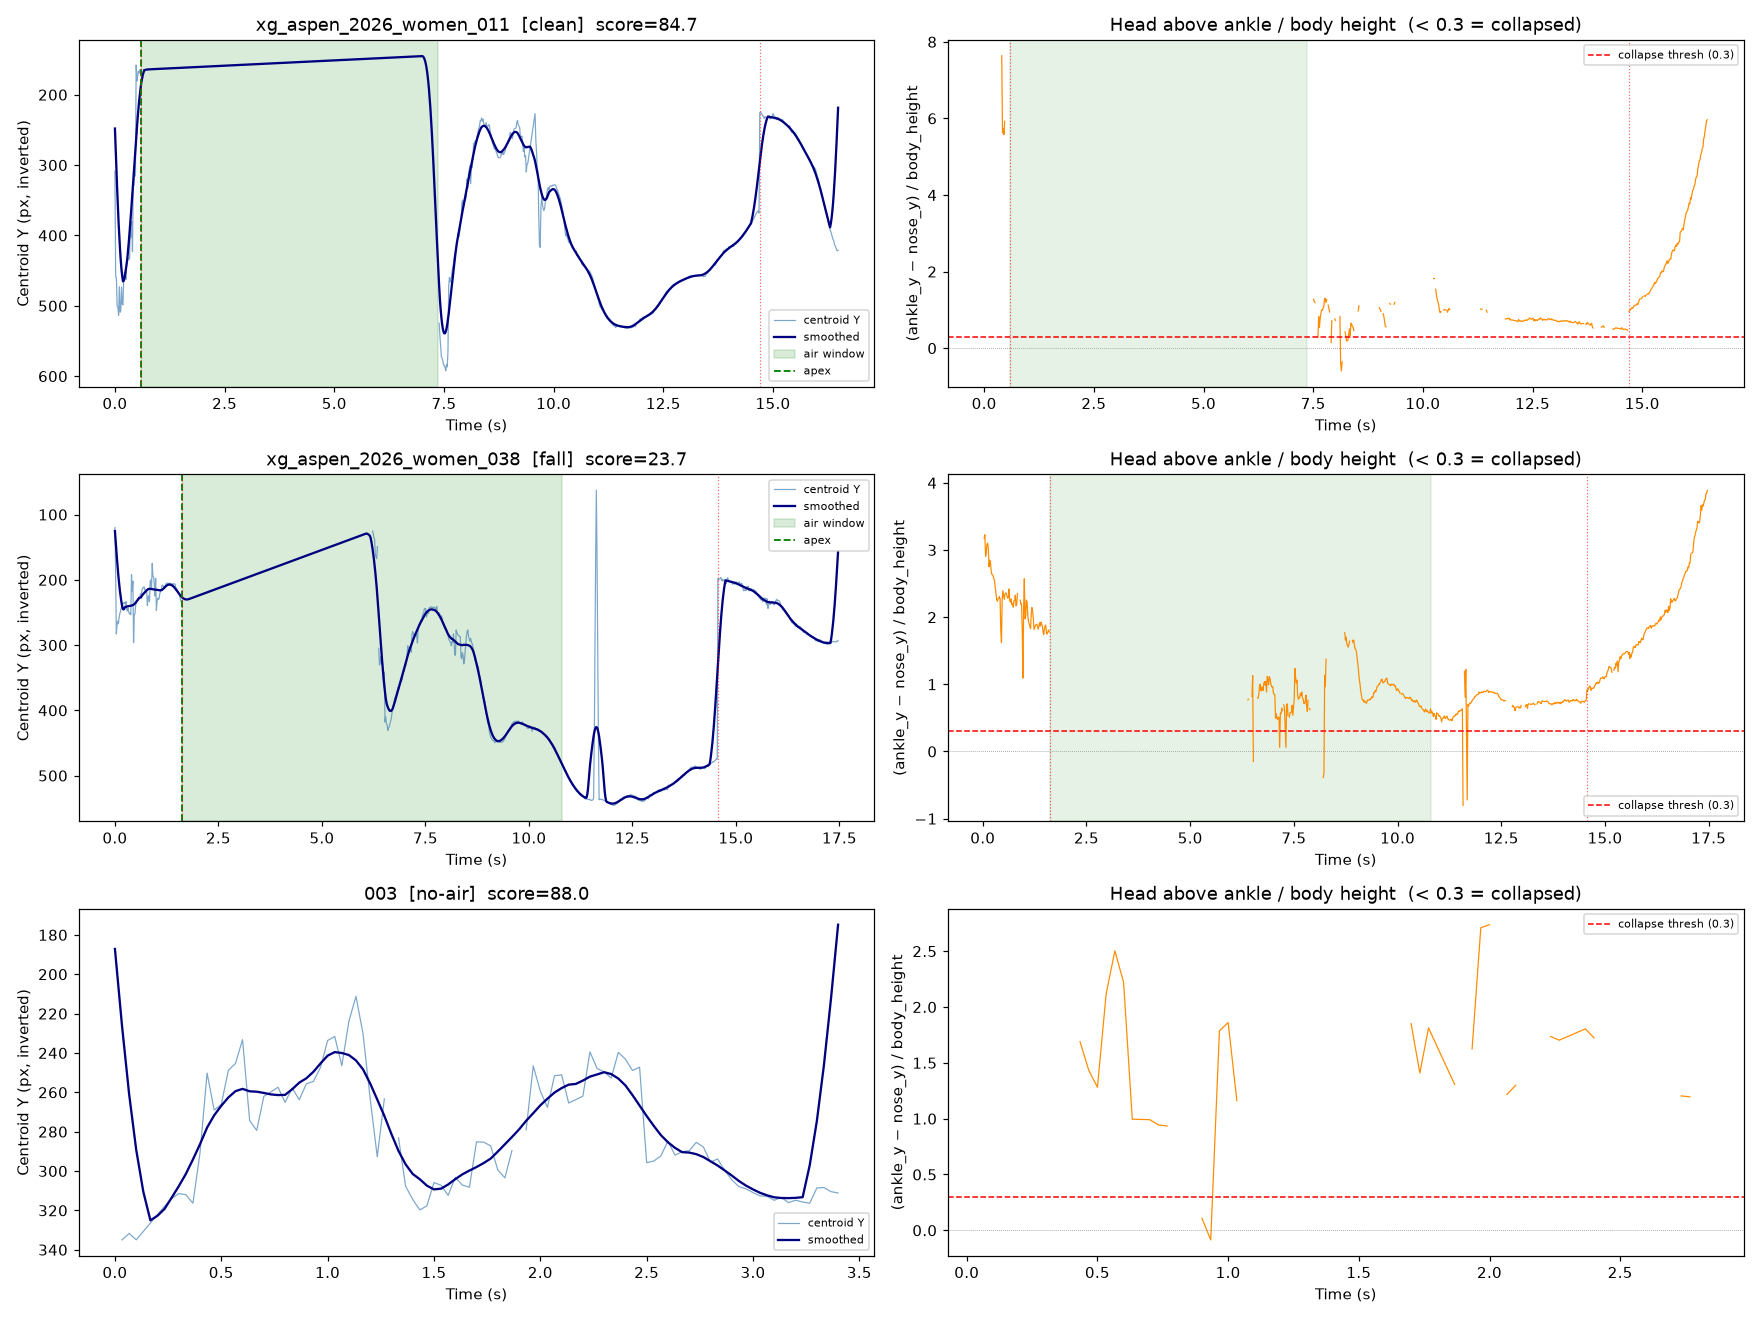

In [7]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

# Pick one clip with air detected and one fall clip for comparison
df_sorted = df.sort_values("air_duration_s", ascending=False)
stems_to_plot = []

# Longest clean air window
clean = df_sorted[(df_sorted["air_detected"] == 1) & (df_sorted["fall"] == 0)]
if len(clean):
    stems_to_plot.append((clean.iloc[0]["filename"], "clean"))
# Fall clip with air detected
falls_det = df_sorted[(df_sorted["air_detected"] == 1) & (df_sorted["fall"] == 1)]
if len(falls_det):
    stems_to_plot.append((falls_det.iloc[0]["filename"], "fall"))
# Clip with no air detected
no_air = df_sorted[df_sorted["air_detected"] == 0]
if len(no_air):
    stems_to_plot.append((no_air.iloc[0]["filename"], "no-air"))

fig, axes = plt.subplots(len(stems_to_plot), 2, figsize=(16, 4 * len(stems_to_plot)))
if len(stems_to_plot) == 1:
    axes = [axes]

for ax_row, (stem, label) in zip(axes, stems_to_plot):
    pf = POSE_DIR / f"{stem}_pose.npy"
    mf = POSE_DIR / f"{stem}_pose_meta.json"
    if not pf.exists():
        continue
    pose_seq = np.load(pf)
    meta = json.loads(mf.read_text()) if mf.exists() else {}
    fps = float(meta.get("fps") or 59.94)
    cuts = sorted(int(c) for c in (meta.get("cut_frames") or []))
    n = len(pose_seq)
    t = np.arange(n) / fps

    row = df[df["filename"] == stem].iloc[0] if stem in df["filename"].values else None

    # Left: centroid Y
    centroids = np.array([body_centroid(f) for f in pose_seq])
    y = centroids[:, 1]
    ax = ax_row[0]
    ax.plot(t, y, lw=0.8, color="steelblue", alpha=0.7, label="centroid Y")
    sigma = max(2, fps / 8)
    y_sm = gaussian_smooth(y, sigma)
    ax.plot(t, y_sm, lw=1.5, color="navy", label="smoothed")
    if row is not None and row["air_detected"] == 1:
        a0, a1 = row["air_start"] / fps, row["air_end"] / fps
        ax.axvspan(a0, a1, alpha=0.15, color="green", label="air window")
        ax.axvline(row["apex_frame"] / fps, color="green", lw=1.2, ls="--", label="apex")
    for c in cuts:
        ax.axvline(c / fps, color="red", lw=0.8, ls=":", alpha=0.6)
    ax.invert_yaxis()
    score_str = f"score={row['target']:.1f}" if row is not None and not np.isnan(row["target"]) else "unscored"
    ax.set_title(f"{stem[:35]}  [{label}]  {score_str}")
    ax.set_ylabel("Centroid Y (px, inverted)")
    ax.set_xlabel("Time (s)")
    ax.legend(fontsize=7)

    # Right: head-above-ankle signal (fall proxy)
    heights  = np.array([body_height_px(f) for f in pose_seq])
    median_h = float(np.nanmedian(heights))
    head_above = np.full(n, np.nan)
    for ti, frame in enumerate(pose_seq):
        if visible(frame, 0, L_ANK, R_ANK):
            nose_y  = float(frame[0, 1])
            ankle_y = float((frame[L_ANK, 1] + frame[R_ANK, 1]) / 2.0)
            head_above[ti] = (ankle_y - nose_y) / max(median_h, 1)

    ax = ax_row[1]
    ax.plot(t, head_above, lw=0.8, color="darkorange")
    ax.axhline(HEAD_COLLAPSE_THR, color="red", lw=1.0, ls="--",
               label=f"collapse thresh ({HEAD_COLLAPSE_THR})")
    ax.axhline(0, color="gray", lw=0.5, ls=":")
    if row is not None and row["air_detected"] == 1:
        a0, a1 = row["air_start"] / fps, row["air_end"] / fps
        ax.axvspan(a0, a1, alpha=0.10, color="green")
    for c in cuts:
        ax.axvline(c / fps, color="red", lw=0.8, ls=":", alpha=0.6)
    ax.set_title("Head above ankle / body height  (< 0.3 = collapsed)")
    ax.set_ylabel("(ankle_y − nose_y) / body_height")
    ax.set_xlabel("Time (s)")
    ax.legend(fontsize=7)

plt.tight_layout()
fig_path = Path("air_phase_sanity.png")
plt.savefig(fig_path, dpi=110)
plt.close()
print(f"Saved → {fig_path}")
try:
    from IPython.display import Image, display
    display(Image(filename=str(fig_path)))
except Exception:
    pass

## Correlation check

Purely diagnostic — no tuning on these numbers.

## Validation against official scores and fall flag\n\nBefore trusting any pose feature, verify the ground truth holds:\n1. Official fall flag → clearly lower score (proves the label is usable)\n2. Our fall-sign features separate fall=1 from fall=0 (proves pose can detect it)\n3. Spearman ρ of each fall-sign feature with the official `fall` label

In [8]:
df = pd.read_csv(OUT_CSV)
scored = df[df["target"].notna() & df["fall"].notna()].copy()
print(f"Clips with both score and fall label: {len(scored)}")
print(f"  fall=0 (clean) : {int((scored['fall']==0).sum())}")
print(f"  fall=1         : {int((scored['fall']==1).sum())}")

# ── 1. Official score by fall flag ────────────────────────────────────────
print("\n=== Official score by fall flag ===")
for fall_val, grp in scored.groupby("fall"):
    s = grp["target"]
    label = "fall" if fall_val == 1 else "clean"
    print(f"  {label:5s} (n={len(grp):3d}):  "
          f"mean={s.mean():.1f}  median={s.median():.1f}  "
          f"min={s.min():.1f}  max={s.max():.1f}")

print()
for ds in sorted(scored["dataset"].unique()):
    grp = scored[scored["dataset"] == ds]
    if grp["fall"].sum() == 0:
        continue
    clean_med = grp[grp["fall"]==0]["target"].median()
    fall_med  = grp[grp["fall"]==1]["target"].median()
    print(f"  {ds}: clean median={clean_med:.1f}  fall median={fall_med:.1f}  "
          f"gap={clean_med-fall_med:.1f} pts  "
          f"(n_fall={int(grp['fall'].sum())})")

# ── 2. Fall-sign features: clean vs fall means ────────────────────────────
fall_feats = ["head_collapse_frac", "body_height_drop", "sudden_stop",
              "air_duration_s", "air_swap_turns", "air_detected"]
fall_feats = [c for c in fall_feats if c in scored.columns]

print("\n=== Feature means: clean vs fall ===")
for feat in fall_feats:
    sub = scored[scored[feat].notna()]
    if len(sub) == 0:
        continue
    clean_m = sub[sub["fall"]==0][feat].mean()
    fall_m  = sub[sub["fall"]==1][feat].mean()
    r = sub[[feat, "fall"]].corr(method="spearman")["fall"][feat]
    direction = "↓fall" if fall_m < clean_m else "↑fall"
    print(f"  {feat:22s}  clean={clean_m:6.3f}  fall={fall_m:6.3f}  "
          f"{direction}  ρ_vs_fall={r:+.3f}")

# ── 3. Spearman ρ of fall-sign features vs target score ───────────────────
print("\n=== Spearman ρ of fall-sign features vs target score ===")
for feat in fall_feats:
    sub = scored[scored[feat].notna()]
    if len(sub) < 5:
        continue
    r = sub[[feat, "target"]].corr(method="spearman")["target"][feat]
    print(f"  {feat:22s}  ρ={r:+.3f}  (n={len(sub)})")

Clips with both score and fall label: 392
  fall=0 (clean) : 321
  fall=1         : 71

=== Official score by fall flag ===
  clean (n=321):  mean=72.5  median=78.0  min=11.0  max=100.0
  fall  (n= 71):  mean=22.8  median=23.7  min=11.5  max=52.0

  aqa7: clean median=72.0  fall median=24.0  gap=48.0 pts  (n_fall=29)
  competition: clean median=83.0  fall median=20.0  gap=63.0 pts  (n_fall=42)

=== Feature means: clean vs fall ===
  head_collapse_frac      clean= 0.014  fall= 0.144  ↑fall  ρ_vs_fall=+0.321
  body_height_drop        clean= 0.967  fall= 0.716  ↓fall  ρ_vs_fall=-0.160
  sudden_stop             clean= 0.805  fall= 0.840  ↑fall  ρ_vs_fall=-0.001
  air_duration_s          clean= 1.795  fall= 1.914  ↑fall  ρ_vs_fall=-0.020
  air_swap_turns          clean= 0.021  fall= 0.032  ↑fall  ρ_vs_fall=+0.020
  air_detected            clean= 0.813  fall= 0.887  ↑fall  ρ_vs_fall=+0.076

=== Spearman ρ of fall-sign features vs target score ===
  head_collapse_frac      ρ=-0.187  (n=320)
 

Saved → score_by_fall.png


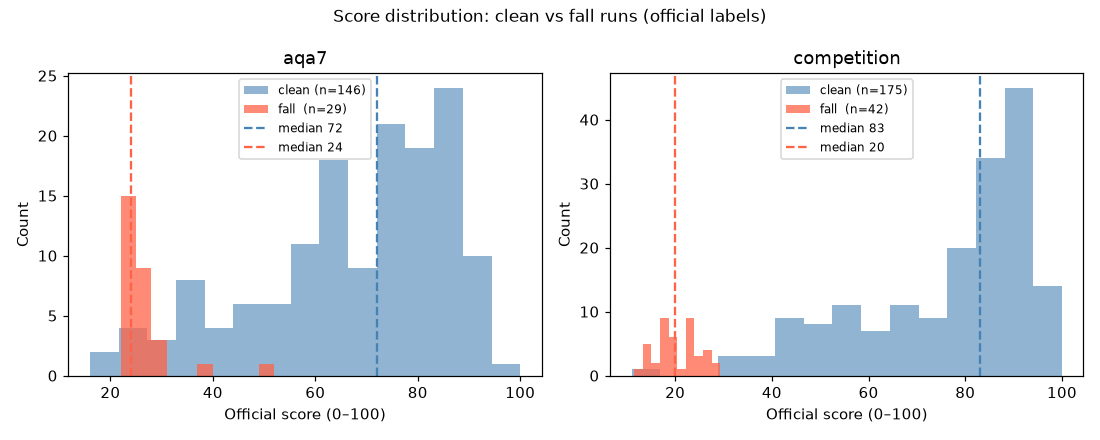

In [9]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

datasets = [d for d in sorted(scored["dataset"].unique())
            if scored[scored["dataset"]==d]["fall"].sum() > 0]
n_ds = max(len(datasets), 1)

fig, axes = plt.subplots(1, n_ds, figsize=(5 * n_ds, 4), sharey=False)
if n_ds == 1:
    axes = [axes]

for ax, ds in zip(axes, datasets):
    grp = scored[scored["dataset"] == ds]
    clean_s = grp[grp["fall"]==0]["target"].dropna()
    fall_s  = grp[grp["fall"]==1]["target"].dropna()
    ax.hist(clean_s, bins=15, alpha=0.6, color="steelblue",
            label=f"clean (n={len(clean_s)})")
    ax.hist(fall_s,  bins=10, alpha=0.75, color="tomato",
            label=f"fall  (n={len(fall_s)})")
    ax.axvline(clean_s.median(), color="steelblue", lw=1.5, ls="--",
               label=f"median {clean_s.median():.0f}")
    ax.axvline(fall_s.median(),  color="tomato",    lw=1.5, ls="--",
               label=f"median {fall_s.median():.0f}")
    ax.set_title(ds)
    ax.set_xlabel("Official score (0–100)")
    ax.set_ylabel("Count")
    ax.legend(fontsize=8)

plt.suptitle("Score distribution: clean vs fall runs (official labels)", fontsize=11)
plt.tight_layout()
fig_path = Path("score_by_fall.png")
plt.savefig(fig_path, dpi=110)
plt.close()
print(f"Saved → {fig_path}")
try:
    from IPython.display import Image, display
    display(Image(filename=str(fig_path)))
except Exception:
    pass

In [10]:
df = pd.read_csv(OUT_CSV)
scored = df[df["target"].notna()].copy()
print(f"Scored clips : {len(scored)}")
print(f"By dataset   : {scored['dataset'].value_counts().to_dict()}")
print(f"Air detected : {int(scored['air_detected'].sum())} / {len(scored)}")

feat_cols = [
    # air phase
    "air_detected", "air_duration_s", "apex_y_norm",
    # spin
    "air_swap_turns", "air_swap_rate_hz", "air_inverted_frac",
    # fall signs
    "head_collapse_frac", "body_height_drop", "sudden_stop",
    # quality
    "pose_coverage",
]
feat_cols = [c for c in feat_cols if c in scored.columns]

corr = (scored[feat_cols + ["target"]]
        .corr(method="spearman")["target"]
        .drop("target")
        .sort_values(key=abs, ascending=False))

print("\nSpearman ρ with target score (whole dataset):")
print(corr.round(3).to_string())

print("\n--- Air-only subset (clips where air was detected) ---")
air_scored = scored[scored["air_detected"] == 1]
if len(air_scored) > 10:
    corr_air = (air_scored[feat_cols + ["target"]]
                .corr(method="spearman")["target"]
                .drop("target")
                .sort_values(key=abs, ascending=False))
    print(f"(n={len(air_scored)})")
    print(corr_air.round(3).to_string())

print("\n--- By dataset ---")
for ds, grp in scored.groupby("dataset"):
    c = (grp[feat_cols + ["target"]]
         .corr(method="spearman")["target"]
         .drop("target"))
    print(f"  {ds} (n={len(grp)}):")
    print("  " + c.round(3).sort_values(key=abs, ascending=False).to_string())
    print()

# Fall classifier check: how well do fall signs separate fall from clean?
print("--- Fall sign means: fall=1 vs fall=0 ---")
fall_feats = ["head_collapse_frac", "body_height_drop", "sudden_stop", "air_duration_s"]
fall_feats = [c for c in fall_feats if c in scored.columns]
fall_comp = scored[scored["fall"].notna()].groupby("fall")[fall_feats].mean()
print(fall_comp.round(3).to_string())

Scored clips : 392
By dataset   : {'competition': 217, 'aqa7': 175}
Air detected : 324 / 392

Spearman ρ with target score (whole dataset):
pose_coverage         0.220
head_collapse_frac   -0.187
apex_y_norm           0.141
body_height_drop      0.114
sudden_stop           0.080
air_detected          0.045
air_swap_rate_hz     -0.022
air_swap_turns       -0.022
air_duration_s        0.014
air_inverted_frac     0.005

--- Air-only subset (clips where air was detected) ---
(n=324)
pose_coverage         0.218
head_collapse_frac   -0.192
apex_y_norm           0.141
body_height_drop      0.103
sudden_stop           0.092
air_swap_rate_hz     -0.022
air_swap_turns       -0.022
air_duration_s        0.014
air_inverted_frac     0.005
air_detected            NaN

--- By dataset ---
  aqa7 (n=175):
  body_height_drop      0.236
pose_coverage         0.167
head_collapse_frac   -0.148
air_inverted_frac     0.139
sudden_stop          -0.110
apex_y_norm           0.089
air_detected         -0.068
ai